In [1]:
import pandas as pd
import matplotlib.pylab as plt
%matplotlib inline
import numpy as np
from astropy.time import Time
from itertools import cycle

from astropy.stats import kuiper

In [2]:
sports_dict = {}
sports_dict["NFL"] = {"data": "../data/nfl_consolidated.csv", "n_year_bins": 6}

sports_dict["NBA"] = {"data": "../data/nba_consolidated.csv", "n_year_bins": 5}

sports_dict["NHL"] = {"data": "../data/hockey_consolidated.csv", "n_year_bins": 5}

sports_dict["MLB"] = {"data": "../data/baseball_consolidated.csv", "n_year_bins": 7,
                     "sept_line": True}

sports_dict["WNBA"] = {"data": "../data/wnba_consolidated.csv", "n_year_bins": 1}



/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 11764 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 11766 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/yoachim/anaconda3/envs/rubin_14/lib/python3.14/site-packages/erfa/core.py:133: ErfaWa

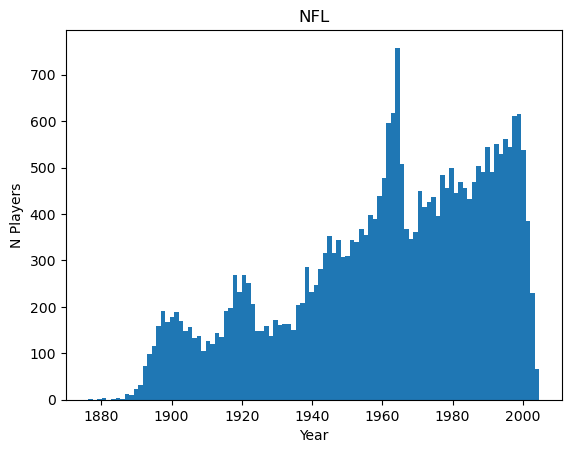

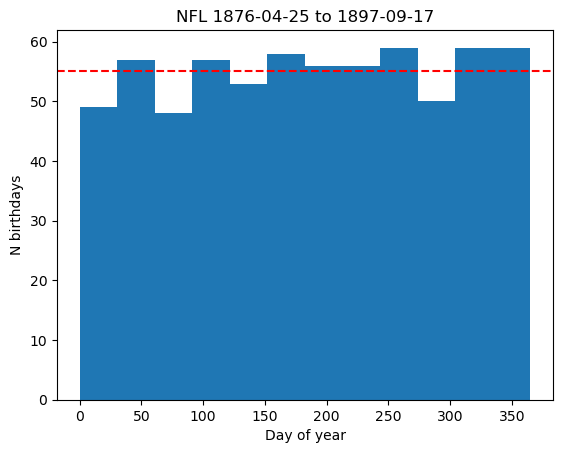

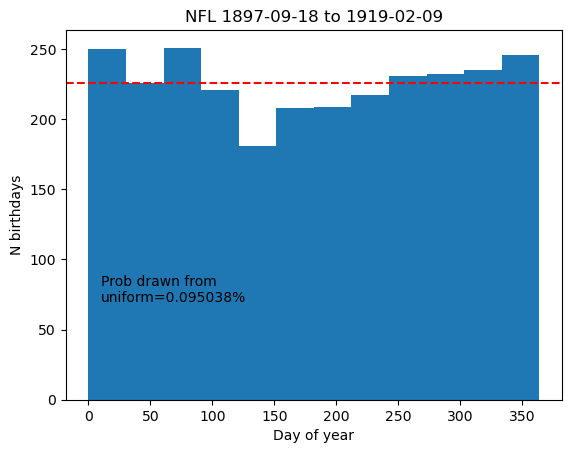

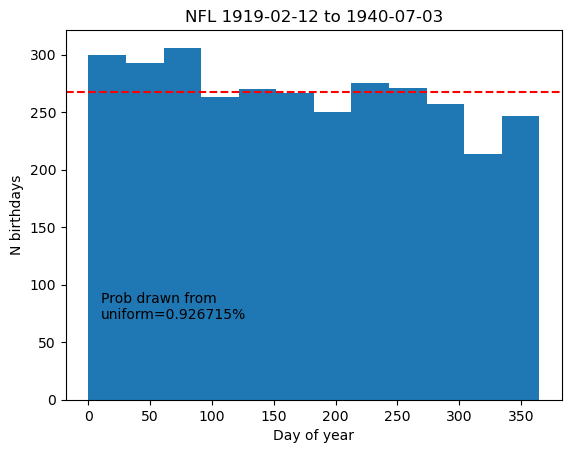

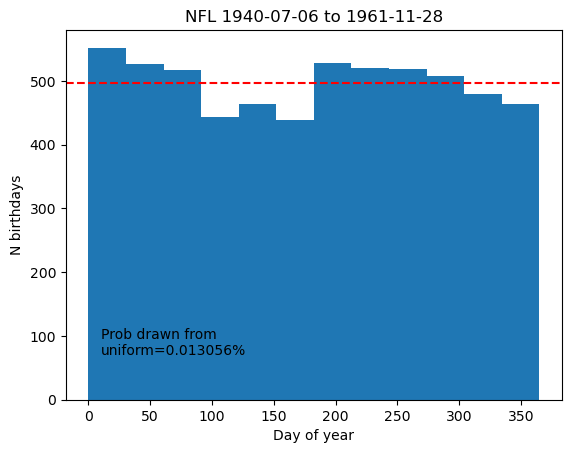

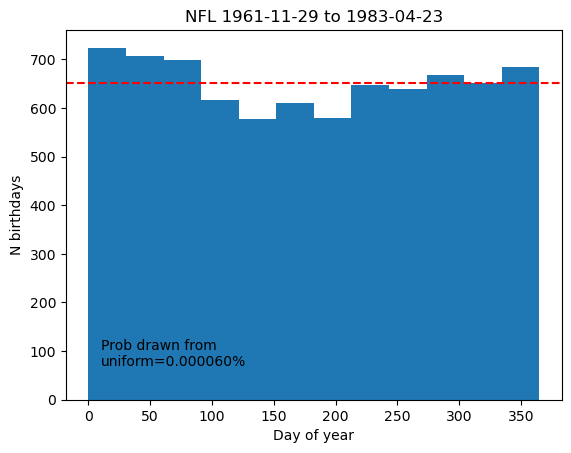

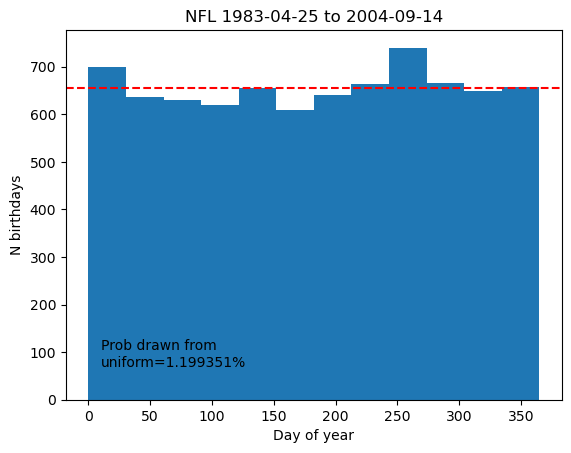

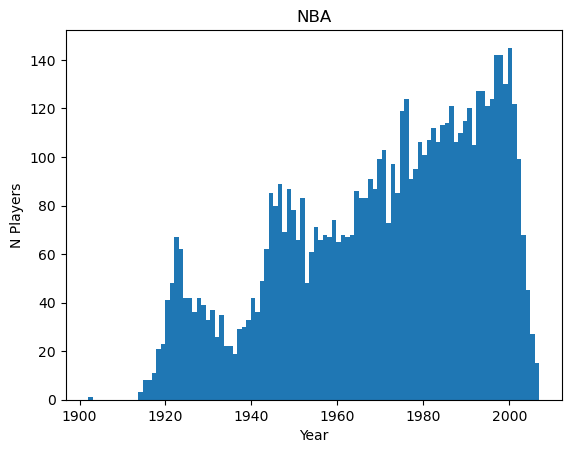

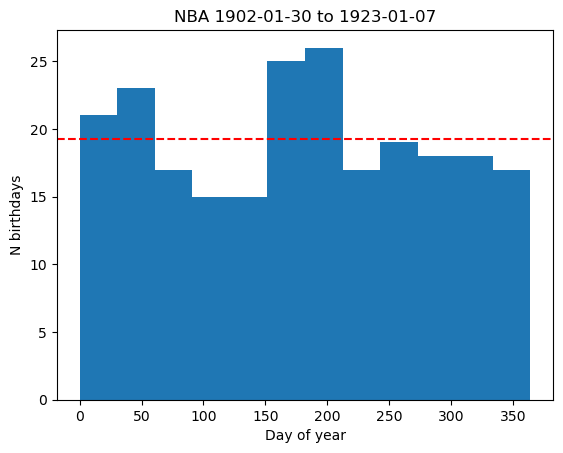

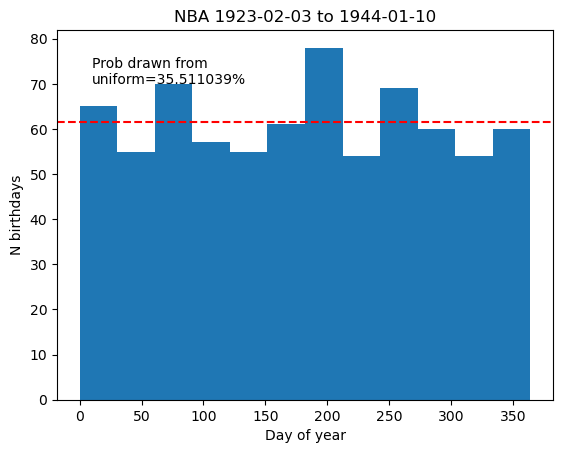

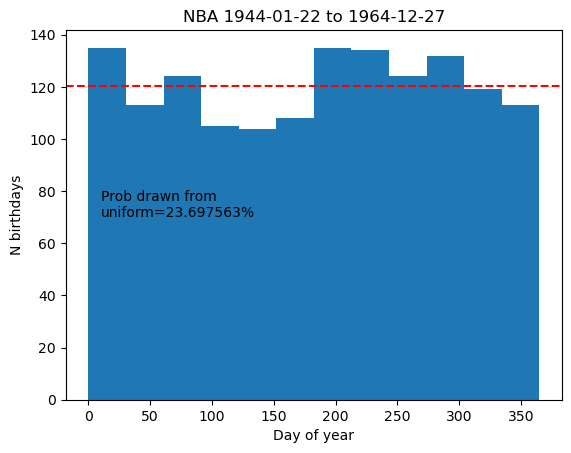

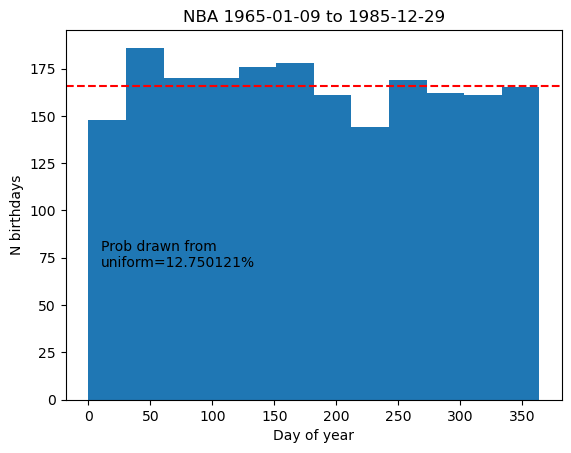

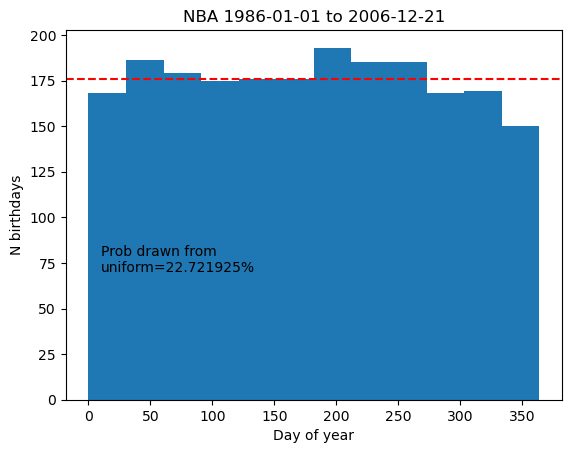

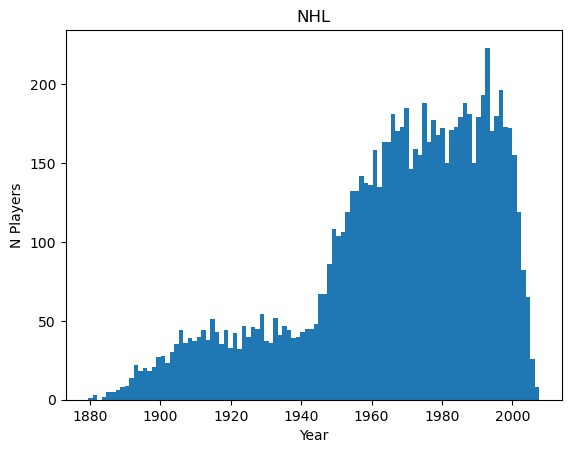

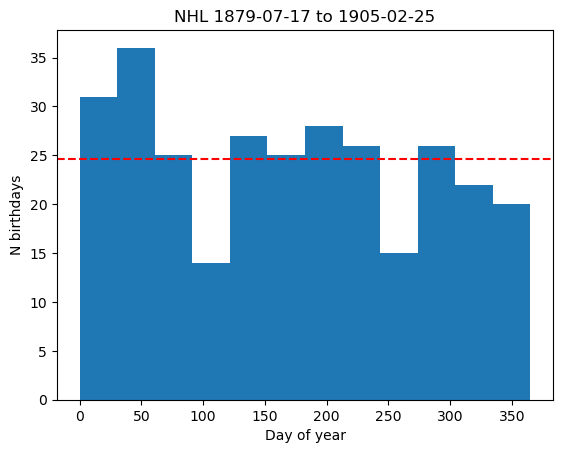

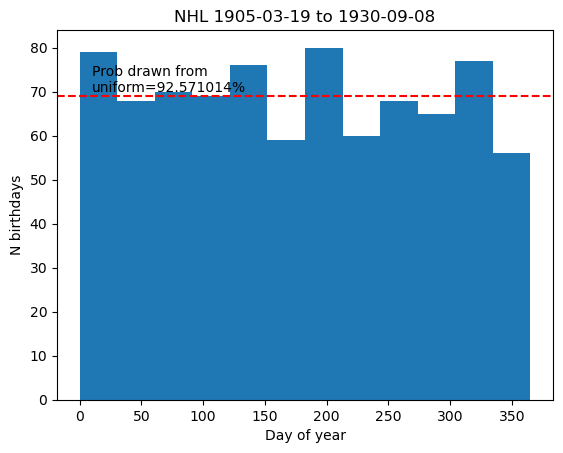

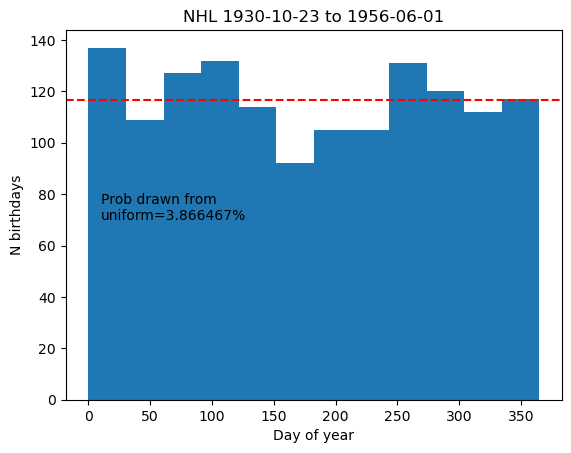

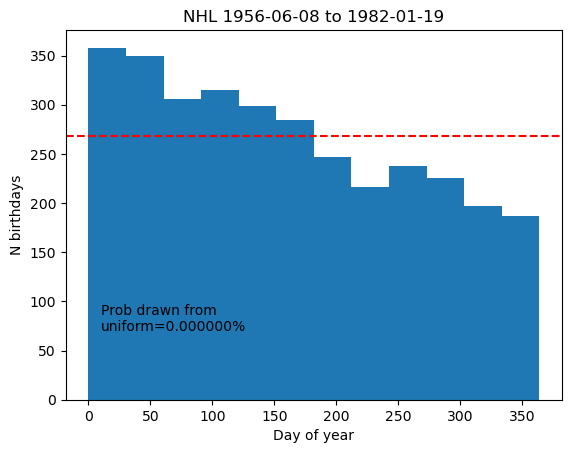

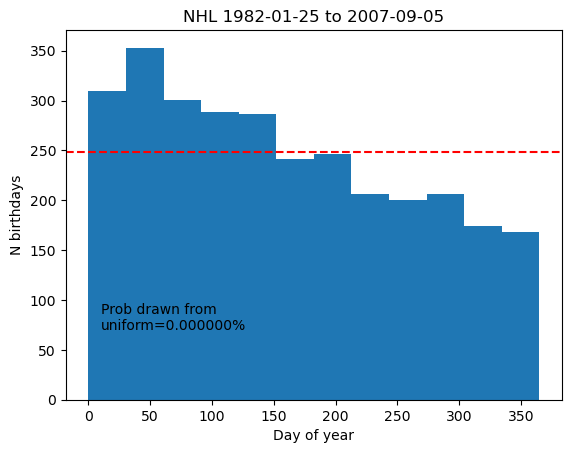

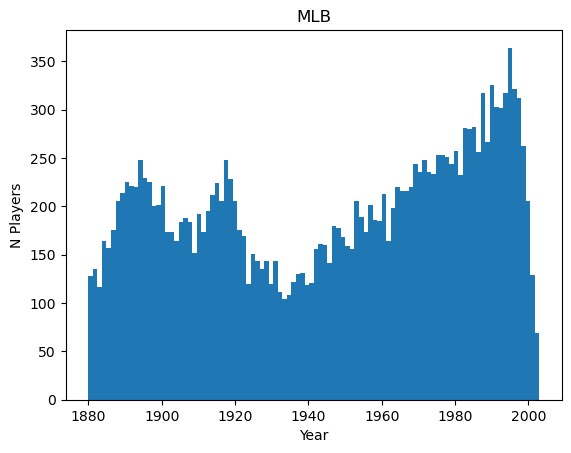

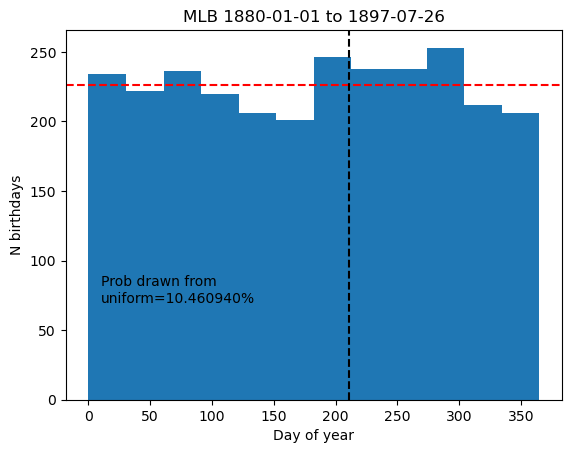

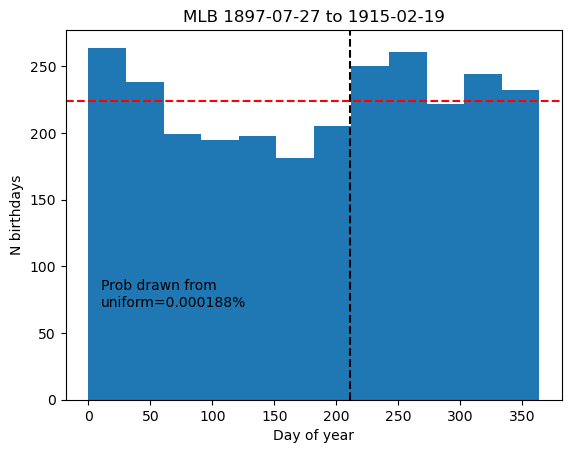

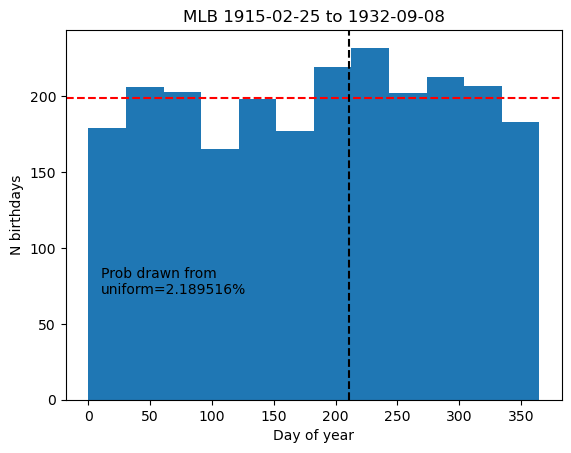

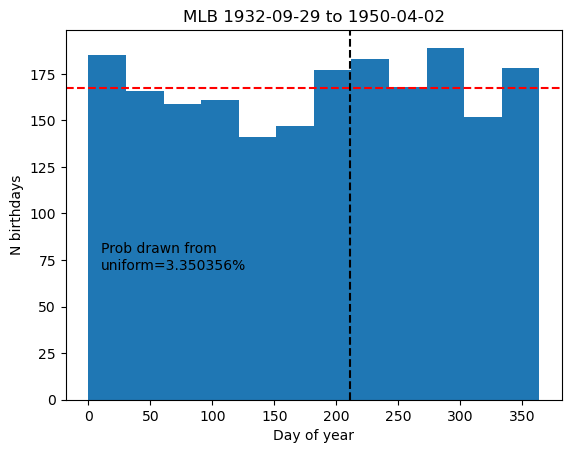

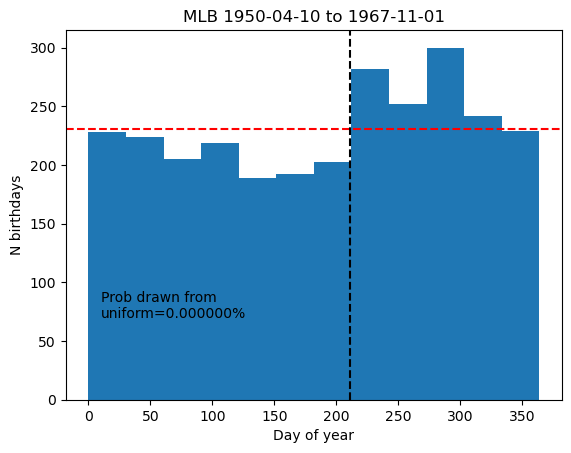

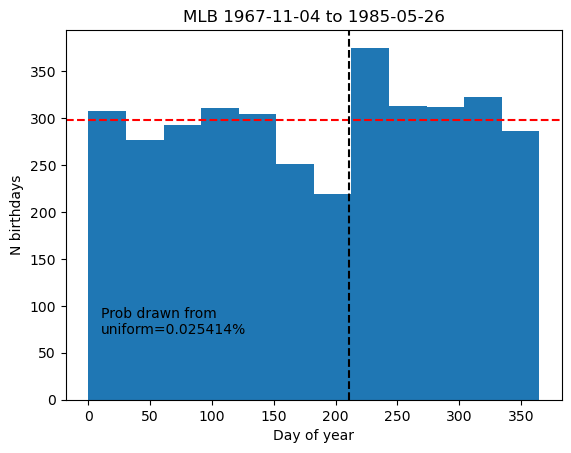

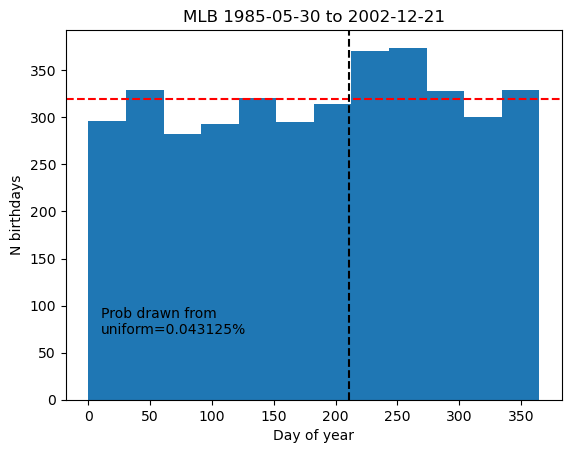

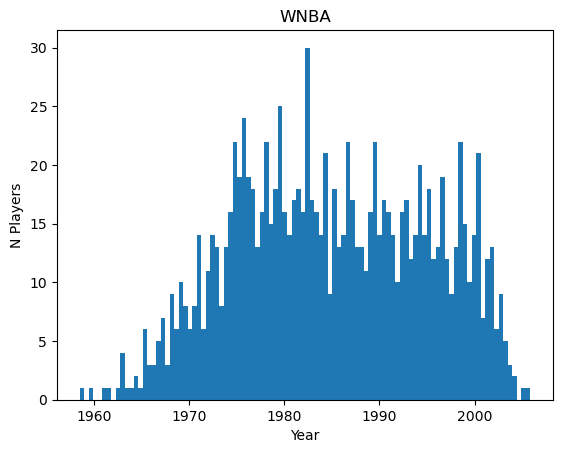

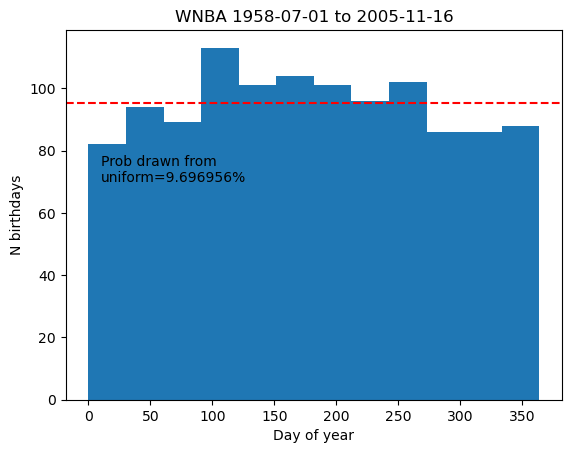

In [3]:
results = {}

for key in sports_dict:
    n_year_bins = sports_dict[key]["n_year_bins"]
    data = pd.read_csv(sports_dict[key]["data"])
    time_str = ["%i-%i-%i" % (d1,d2,d3) for d1,d2,d3 in zip(data["year"].values.astype(int),
                                                            data["month"].values.astype(int), 
                                                            data["day"].values.astype(int))]
    times = Time(time_str)

    
    mjd_1900 = Time("1900-01-01").mjd
    fig, ax = plt.subplots()
    _temp = ax.hist((times.mjd-mjd_1900)/365.25 + 1900, bins=100)
    ax.set_xlabel("Year")
    ax.set_ylabel("N Players")
    ax.set_title(key)


    jan_1 = Time(["%i-01-01" % d for d in data["year"]])
    t_to_j1 = times.mjd - jan_1.mjd

    sept_1_day = Time("1970-07-31").mjd - Time("1970-01-01").mjd 

    edges = np.linspace(times.mjd.min(), times.mjd.max()+1, n_year_bins+1)
    ds = []
    fpps = []
    for lower,upper in zip(edges[0:-1], edges[1:]):
        in_range = np.where((times.mjd >= lower) & (times.mjd < upper))
        fig,ax = plt.subplots()
        _temp = ax.hist(t_to_j1[in_range], bins=12)
        ax.set_xlabel("Day of year")
        ax.set_ylabel("N birthdays")
        t1_str = str(times[in_range].min()).split(" ")[0]
        t2_str = str(times[in_range].max()).split(" ")[0]
        ax.set_title(key + " "+ t1_str + " to " + t2_str)
    
        
        d, fpp = kuiper(t_to_j1[in_range]/365)
    
        ds.append(d)
        fpps.append(fpp)
    
        ax.annotate("Prob drawn from \nuniform=%f%%" % (fpp*100), [10, 70])
        ax.axhline(np.mean(_temp[0]), color="red", linestyle='--')
        if "sept_line" in  sports_dict[key].keys():
            ax.axvline(x=sept_1_day, color="black", linestyle='--')

    results[key] = {"fpps": fpps, "edges": edges, "ds":ds}

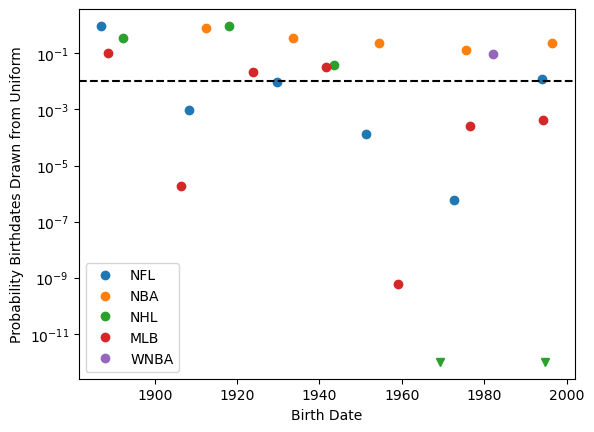

In [8]:
fig, ax = plt.subplots()
min_val = 1e-12
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

for key in results:
    mid_bin = (results[key]["edges"][0:-1]+results[key]["edges"][1:])/2
    mbt = Time(mid_bin, format="mjd")
    fpps = np.array(results[key]["fpps"])

    above = np.where(fpps >= min_val)[0]
    below = np.where(fpps < min_val)[0]
    color = next(colors)
    ax.semilogy(mbt.to_datetime()[above], fpps[above], "o", label=key, color=color)
    if np.size(below) > 0:
        ax.semilogy(mbt.to_datetime()[below], [min_val]*below.size, "v", color=color)
    
    
    
ax.set_xlabel("Birth Date")
ax.set_ylabel("Probability Birthdates Drawn from Uniform")
ax.axhline(0.01, color="black", linestyle='--')
leg = ax.legend()

In [5]:
results["NFL"]["ds"]

[np.float64(0.0333699459100989),
 np.float64(0.0442546214532592),
 np.float64(0.035387061978520484),
 np.float64(0.03277004737854794),
 np.float64(0.03448243184905181),
 np.float64(0.022218352716654066)]

In [6]:
results["NHL"]["ds"]

[np.float64(0.07638727652658459),
 np.float64(0.030799556078249357),
 np.float64(0.04761178414635342),
 np.float64(0.09889705413572819),
 np.float64(0.10547715439794503)]

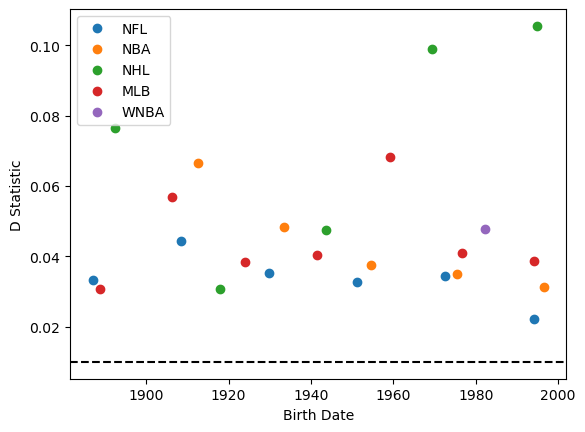

In [9]:
fig, ax = plt.subplots()
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

for key in results:
    mid_bin = (results[key]["edges"][0:-1]+results[key]["edges"][1:])/2
    mbt = Time(mid_bin, format="mjd")
    ds = np.array(results[key]["ds"])

    
    color = next(colors)
    ax.plot(mbt.to_datetime(), ds, "o", label=key, color=color)
    
    
    
    
ax.set_xlabel("Birth Date")
ax.set_ylabel("D Statistic")
ax.axhline(0.01, color="black", linestyle='--')
leg = ax.legend()